In [42]:
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules

warnings.filterwarnings("ignore", category=DeprecationWarning)

In [4]:
#load the dataset
df = pd.read_csv("/orders.csv")

In [5]:
#check dataset dimensions
print("Dataset shape:",df.shape)

Dataset shape: (2000, 16)


In [6]:
#column names
print("\nColumns:")
print(df.columns.tolist())


Columns:
['id', 'customer_id', 'restaurant_id', 'driver_id', 'order_timestamp', 'items', 'item_count', 'subtotal', 'delivery_fee', 'tip', 'total', 'estimated_delivery_min', 'actual_delivery_min', 'status', 'cancellation_reason', 'rating']


In [7]:
display(df.head())

,id,customer_id,restaurant_id,driver_id,order_timestamp,items,item_count,subtotal,delivery_fee,tip,total,estimated_delivery_min,actual_delivery_min,status,cancellation_reason,rating
0,1,2908,2,10,1/1/2024 11:03,"Chicken Tenders Basket, Margherita Pizza",2,32.43,4.99,6.11,43.53,29,31.0,delivered,NaN,4.0
1,2,4781,85,12,1/1/2024 11:13,"Pepperoni Pizza Large, Pad Thai, Fish Tacos",3,44.70,4.99,12.61,62.30,32,37.0,delivered,NaN,3.0
2,3,4593,117,21,1/1/2024 11:27,"Pad Thai, Caesar Salad, Fish Tacos, Brisket Plate",4,44.84,4.99,3.21,53.04,33,36.0,delivered,NaN,3.0
3,4,1375,35,16,1/1/2024 11:28,10-Piece Wings,1,11.27,4.99,1.00,17.26,20,23.0,delivered,NaN,4.0
4,5,2068,2,37,1/1/2024 11:31,"Lamb Vindaloo, Margherita Pizza, 10-Piece Wings",3,42.09,4.99,10.69,57.77,43,46.0,delivered,NaN,3.0


In [8]:
# check for any missing values
print("\nMissing values")
print(df.isnull().sum())


Missing values
id                           0
customer_id                  0
restaurant_id                0
driver_id                    0
order_timestamp              0
items                        0
item_count                   0
subtotal                     0
delivery_fee                 0
tip                          0
total                        0
estimated_delivery_min       0
actual_delivery_min        172
status                       0
cancellation_reason       1828
rating                     172
dtype: int64


In [9]:
#display first 10 orders
for i, items in enumerate(df['items'].head(10),start=1):
  print(f"Order{i}:{items}")
  print("Data type",type(items).__name__)
  print("-"*40)

Order1:Chicken Tenders Basket, Margherita Pizza
Data type str
----------------------------------------
Order2:Pepperoni Pizza Large, Pad Thai, Fish Tacos
Data type str
----------------------------------------
Order3:Pad Thai, Caesar Salad, Fish Tacos, Brisket Plate
Data type str
----------------------------------------
Order4:10-Piece Wings
Data type str
----------------------------------------
Order5:Lamb Vindaloo, Margherita Pizza, 10-Piece Wings
Data type str
----------------------------------------
Order6:Lamb Vindaloo, Classic Cheeseburger, Green Curry
Data type str
----------------------------------------
Order7:BBQ Pulled Pork Sandwich, Acai Bowl
Data type str
----------------------------------------
Order8:Green Curry, Pho Bo, Classic Cheeseburger, Pepperoni Pizza Large
Data type str
----------------------------------------
Order9:Classic Cheeseburger, Brisket Plate, Pepperoni Pizza Large, Salmon Roll Combo
Data type str
----------------------------------------
Order10:Acai Bow

In [10]:
# Preprocessing
print("Total rows:", len(df))
print("Unique order IDs:", df["id"].nunique())

# 1. Checking order statuses
print("\nOrder status counts:")
print(df["status"].value_counts(dropna=False))

# 2. Checking duplicate order IDs
print("\nDuplicate order IDs:", df["id"].duplicated().sum())

# 3. Checking for empty item lists
print("\nEmpty item values:", df["items"].isna().sum())

# 4. Checking for duplicate food names within each order
def parse_items(items):
    return [item.strip() for item in items.split(",") if item.strip()]

df["basket"] = df["items"].apply(parse_items)

duplicate_item_orders = df["basket"].apply(
    lambda basket: len(basket) != len(set(basket))
).sum()

print("Orders with repeated food names:", duplicate_item_orders)

# Display the transformed transactions
display(df[["id", "items", "basket"]].head())

Total rows: 2000
Unique order IDs: 2000

Order status counts:
status
delivered    1828
cancelled     172
Name: count, dtype: int64

Duplicate order IDs: 0

Empty item values: 0
Orders with repeated food names: 0


,id,items,basket
0,1,"Chicken Tenders Basket, Margherita Pizza","[Chicken Tenders Basket, Margherita Pizza]"
1,2,"Pepperoni Pizza Large, Pad Thai, Fish Tacos","[Pepperoni Pizza Large, Pad Thai, Fish Tacos]"
2,3,"Pad Thai, Caesar Salad, Fish Tacos, Brisket Plate","[Pad Thai, Caesar Salad, Fish Tacos, Brisket P..."
3,4,10-Piece Wings,[10-Piece Wings]
4,5,"Lamb Vindaloo, Margherita Pizza, 10-Piece Wings","[Lamb Vindaloo, Margherita Pizza, 10-Piece Wings]"


In [11]:
# Keeping only successfully delivered orders
df_clean = df[df["status"] == "delivered"].copy()

# Checking the results
print("Original orders:", len(df))
print("Orders retained:", len(df_clean))
print("Orders removed:", len(df) - len(df_clean))

# Creating transaction baskets
transactions = df_clean["basket"].tolist()

print("\nFirst 5 transactions:")
for transaction in transactions[:5]:
    print(transaction)

Original orders: 2000
Orders retained: 1828
Orders removed: 172

First 5 transactions:
['Chicken Tenders Basket', 'Margherita Pizza']
['Pepperoni Pizza Large', 'Pad Thai', 'Fish Tacos']
['Pad Thai', 'Caesar Salad', 'Fish Tacos', 'Brisket Plate']
['10-Piece Wings']
['Lamb Vindaloo', 'Margherita Pizza', '10-Piece Wings']


In [12]:
# Converting transactions into one-hot encoding table for Apriori
encoder = TransactionEncoder()
encoded_array = encoder.fit(transactions).transform(transactions)

basket_df = pd.DataFrame(
  encoded_array,
  columns = encoder.columns_
)

display(basket_df.head())
print("Number of transactions:", basket_df.shape[0])
print("Number of unique food items:", basket_df.shape[1])

,10-Piece Wings,Acai Bowl,BBQ Pulled Pork Sandwich,Brisket Plate,Butter Chicken,Caesar Salad,Chicken Burrito Bowl,Chicken Tenders Basket,Classic Cheeseburger,Dragon Roll,Fish Tacos,General Tso's Chicken,Green Curry,Kung Pao Chicken,Lamb Vindaloo,Margherita Pizza,Pad Thai,Pepperoni Pizza Large,Pho Bo,Salmon Roll Combo
0,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,True,True,False,False
2,False,False,False,True,False,True,False,False,False,False,True,False,False,False,False,False,True,False,False,False
3,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,True,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,False,False,False


Number of transactions: 1828
Number of unique food items: 20


In [13]:
# Counting how many transactions contain each food item
item_counts = basket_df.sum().sort_values(ascending=False)

# Calculating support for each item
item_support = item_counts / len(basket_df)

# Creating a summary table
item_summary = pd.DataFrame({
    "Item": item_counts.index,
    "Transaction Count": item_counts.values,
    "Support": item_support[item_counts.index].values,
    "Support (%)": (item_support[item_counts.index].values * 100).round(2)
})

display(item_summary)

,Item,Transaction Count,Support,Support (%)
0,Pad Thai,262,0.143326,14.33
1,Lamb Vindaloo,252,0.137856,13.79
2,Green Curry,249,0.136214,13.62
3,Pho Bo,247,0.135120,13.51
4,Chicken Burrito Bowl,244,0.133479,13.35
5,Butter Chicken,237,0.129650,12.96
6,BBQ Pulled Pork Sandwich,237,0.129650,12.96
7,Caesar Salad,235,0.128556,12.86
8,Chicken Tenders Basket,235,0.128556,12.86
9,Dragon Roll,226,0.123632,12.36


In [21]:
# minimum threshold support 1%
frequent_itemsets_1pct = apriori(
    basket_df,
    min_support=0.01,
    use_colnames=True
)

# Count itemsets by size
frequent_itemsets_1pct["itemset_size"] = (
    frequent_itemsets_1pct["itemsets"].apply(len)
)

print("Total frequent itemsets:", len(frequent_itemsets_1pct))

print("\nItemsets by size:")
print(
    frequent_itemsets_1pct["itemset_size"]
    .value_counts()
    .sort_index()
)

# Display pairs only
pairs = frequent_itemsets_1pct[
    frequent_itemsets_1pct["itemset_size"] == 2
].sort_values("support", ascending=False)

display(pairs)

Total frequent itemsets: 183

Itemsets by size:
itemset_size
1     20
2    163
Name: count, dtype: int64


,support,itemsets,itemset_size
54,0.020788,"(BBQ Pulled Pork Sandwich, Dragon Roll)",2
110,0.020788,"(Pad Thai, Chicken Burrito Bowl)",2
80,0.020788,"(Butter Chicken, Chicken Tenders Basket)",2
160,0.020241,"(Green Curry, Lamb Vindaloo)",2
79,0.019694,"(Butter Chicken, Chicken Burrito Bowl)",2
...,...,...,...
75,0.010394,"(Brisket Plate, Pepperoni Pizza Large)",2
72,0.010394,"(Brisket Plate, Kung Pao Chicken)",2
133,0.010394,"(Salmon Roll Combo, Classic Cheeseburger)",2
161,0.010394,"(Green Curry, Margherita Pizza)",2


In [23]:
# Selecting the frequent pairs from your 1% support results
pairs = frequent_itemsets_1pct[
    frequent_itemsets_1pct["itemsets"].apply(len) == 2
].copy()

# Sorting by support, highest first
pairs = pairs.sort_values("support", ascending=False)

# Displaying the 10 most frequent pairs
display(pairs.head(10))

,support,itemsets,itemset_size
54,0.020788,"(BBQ Pulled Pork Sandwich, Dragon Roll)",2
110,0.020788,"(Pad Thai, Chicken Burrito Bowl)",2
80,0.020788,"(Butter Chicken, Chicken Tenders Basket)",2
160,0.020241,"(Green Curry, Lamb Vindaloo)",2
79,0.019694,"(Butter Chicken, Chicken Burrito Bowl)",2
97,0.019147,"(Green Curry, Caesar Salad)",2
166,0.018600,"(Lamb Vindaloo, Kung Pao Chicken)",2
105,0.018053,"(Chicken Burrito Bowl, Fish Tacos)",2
101,0.018053,"(Pho Bo, Caesar Salad)",2
159,0.018053,"(Green Curry, Kung Pao Chicken)",2


In [28]:
# generating rules from frequent itemsets to caluclate support, confidence and lift
rules_clean = association_rules(
    frequent_itemsets_1pct.drop(
        columns=["itemset_size"], errors="ignore"
    ),
    metric="confidence",
    min_threshold=0.10
)

# Convert frozensets into readable text
rules_clean["antecedents"] = rules_clean["antecedents"].apply(
    lambda items: ", ".join(sorted(items))
)
rules_clean["consequents"] = rules_clean["consequents"].apply(
    lambda items: ", ".join(sorted(items))
)

# Sort and display the rules
rules_clean = rules_clean.sort_values(
    ["lift", "confidence"], ascending=False
).reset_index(drop=True)

display(
    rules_clean[
        ["antecedents", "consequents",
         "support", "confidence", "lift"]
    ].head(10).round(4)
)

print("Total rules:", len(rules_clean))

,antecedents,consequents,support,confidence,lift
0,BBQ Pulled Pork Sandwich,Dragon Roll,0.0208,0.1603,1.2969
1,Dragon Roll,BBQ Pulled Pork Sandwich,0.0208,0.1681,1.2969
2,Butter Chicken,Chicken Tenders Basket,0.0208,0.1603,1.2472
3,Chicken Tenders Basket,Butter Chicken,0.0208,0.1617,1.2472
4,Fish Tacos,Classic Cheeseburger,0.0164,0.1456,1.2382
5,Classic Cheeseburger,Fish Tacos,0.0164,0.1395,1.2382
6,Fish Tacos,Chicken Burrito Bowl,0.0181,0.1602,1.2001
7,Chicken Burrito Bowl,Fish Tacos,0.0181,0.1352,1.2001
8,Chicken Tenders Basket,General Tso's Chicken,0.0181,0.1404,1.1409
9,General Tso's Chicken,Chicken Tenders Basket,0.0181,0.1467,1.1409


Total rules: 217


In [34]:
"""recommend food function -> selected_items: list of foods already in the basket, rules_df: generated association rules,
top_n: maximum number of recommendations"""

def recommend_food(selected_items, rules_df, top_n=5):
    selected_items = set(selected_items)
    recommendations = []

    for _, rule in rules_df.iterrows():
        antecedent = set(rule["antecedents"].split(", "))
        consequent = set(rule["consequents"].split(", "))

        if antecedent.issubset(selected_items):
            new_items = consequent - selected_items

            for item in new_items:
                recommendations.append({
                    "Recommended item": item,
                    "Based on": rule["antecedents"],
                    "Support": rule["support"],
                    "Confidence": rule["confidence"],
                    "Lift": rule["lift"]
                })

    columns = [
        "Recommended item", "Based on",
        "Support", "Confidence", "Lift"
    ]

    if not recommendations:
        return pd.DataFrame(columns=columns)

    result = pd.DataFrame(recommendations)

    result = result[result["Lift"] > 1]

    result = (
        result.sort_values(
            ["Lift", "Confidence"],
            ascending=False
        )
        .drop_duplicates(subset=["Recommended item"])
        .head(top_n)
        .reset_index(drop=True)
    )

    return result

In [35]:
# testing my rules:
recommendations = recommend_food(
    ["BBQ Pulled Pork Sandwich"],
    rules_clean,
    top_n=5
)
display(recommendations.round(4))

,Recommended item,Based on,Support,Confidence,Lift
0,Dragon Roll,BBQ Pulled Pork Sandwich,0.0208,0.1603,1.2969
1,Acai Bowl,BBQ Pulled Pork Sandwich,0.0170,0.1308,1.0771


In [36]:
recommendations = recommend_food(
    ["Pad Thai"],
    rules_clean,
    top_n=5
)

display(recommendations.round(4))

,Recommended item,Based on,Support,Confidence,Lift
0,Chicken Burrito Bowl,Pad Thai,0.0208,0.145,1.0866


In [37]:
# Evaluation:
test_baskets = [
    ["BBQ Pulled Pork Sandwich"],
    ["Pad Thai"],
    ["Butter Chicken"],
    ["Fish Tacos"],
    ["Dragon Roll"]
]

for basket in test_baskets:
    print(f"\nSelected Basket: {basket}")

    recommendations = recommend_food(
        basket,
        rules_clean,
        top_n=5
    )

    display(recommendations.round(4))


Selected Basket: ['BBQ Pulled Pork Sandwich']


,Recommended item,Based on,Support,Confidence,Lift
0,Dragon Roll,BBQ Pulled Pork Sandwich,0.0208,0.1603,1.2969
1,Acai Bowl,BBQ Pulled Pork Sandwich,0.0170,0.1308,1.0771



Selected Basket: ['Pad Thai']


,Recommended item,Based on,Support,Confidence,Lift
0,Chicken Burrito Bowl,Pad Thai,0.0208,0.145,1.0866



Selected Basket: ['Butter Chicken']


,Recommended item,Based on,Support,Confidence,Lift
0,Chicken Tenders Basket,Butter Chicken,0.0208,0.1603,1.2472
1,Chicken Burrito Bowl,Butter Chicken,0.0197,0.1519,1.1380
2,10-Piece Wings,Butter Chicken,0.0170,0.1308,1.0674
3,Pepperoni Pizza Large,Butter Chicken,0.0153,0.1181,1.0639
4,General Tso's Chicken,Butter Chicken,0.0164,0.1266,1.0284



Selected Basket: ['Fish Tacos']


,Recommended item,Based on,Support,Confidence,Lift
0,Classic Cheeseburger,Fish Tacos,0.0164,0.1456,1.2382
1,Chicken Burrito Bowl,Fish Tacos,0.0181,0.1602,1.2001
2,Salmon Roll Combo,Fish Tacos,0.0142,0.1262,1.1039
3,Kung Pao Chicken,Fish Tacos,0.0148,0.1311,1.0649



Selected Basket: ['Dragon Roll']


,Recommended item,Based on,Support,Confidence,Lift
0,BBQ Pulled Pork Sandwich,Dragon Roll,0.0208,0.1681,1.2969
1,Salmon Roll Combo,Dragon Roll,0.0153,0.1239,1.0836
2,Pho Bo,Dragon Roll,0.0175,0.1416,1.0479


In [39]:
# Comparing different support thresholds to see how changing minimum support affects the number of frequent itemsets.
support_values = [0.01, 0.02, 0.03, 0.05]

comparison = []

for support in support_values:
    itemsets = apriori(
        basket_df,
        min_support=support,
        use_colnames=True
    )

    comparison.append({
        "Minimum Support": support,
        "Frequent Itemsets": len(itemsets),
        "Pairs": sum(itemsets["itemsets"].apply(len) == 2)
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df)

,Minimum Support,Frequent Itemsets,Pairs
0,0.01,183,163
1,0.02,24,4
2,0.03,20,0
3,0.05,20,0


I selected a minimum support of 1% because higher thresholds eliminated most food combinations. However, lower support also means some patterns are based on relatively few orders

In [41]:
# Comparing confidence thresholds
confidence_values = [0.10, 0.15, 0.20, 0.25]

confidence_comparison = []

for confidence in confidence_values:
    temp_rules = association_rules(
        frequent_itemsets_1pct,
        metric="confidence",
        min_threshold=confidence
    )

    confidence_comparison.append({
        "Minimum Confidence": confidence,
        "Total Rules": len(temp_rules),
        "Rules with Lift > 1": sum(temp_rules["lift"] > 1)
    })

confidence_df = pd.DataFrame(confidence_comparison)

display(confidence_df)

,Minimum Confidence,Total Rules,Rules with Lift > 1
0,0.10,217,68
1,0.15,8,8
2,0.20,0,0
3,0.25,0,0


**Support 1%, Confidence 10%** and then filtering recommendations using **lift>1** gives us 68 positive association rules

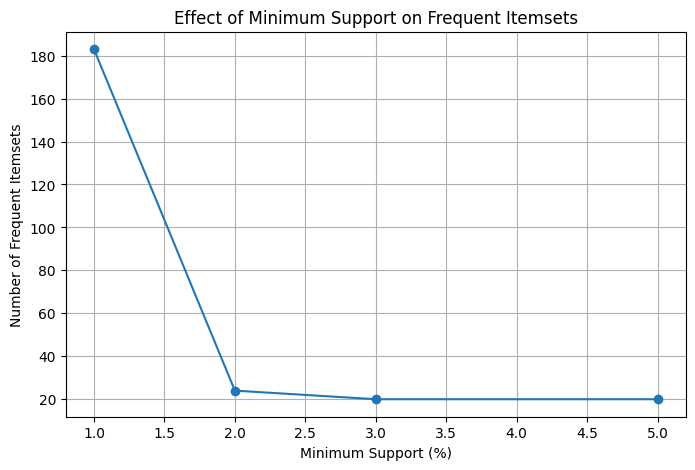

In [43]:
# Visualization
plt.figure(figsize=(8, 5))

plt.plot(
    comparison_df["Minimum Support"] * 100,
    comparison_df["Frequent Itemsets"],
    marker="o"
)

plt.xlabel("Minimum Support (%)")
plt.ylabel("Number of Frequent Itemsets")
plt.title("Effect of Minimum Support on Frequent Itemsets")
plt.grid(True)

plt.show()

In [45]:
# Top 10 rules
top_10_rules = rules_clean[
    rules_clean["lift"] > 1
].head(10)

display(
    top_10_rules[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ].round(4)
)

,antecedents,consequents,support,confidence,lift
0,BBQ Pulled Pork Sandwich,Dragon Roll,0.0208,0.1603,1.2969
1,Dragon Roll,BBQ Pulled Pork Sandwich,0.0208,0.1681,1.2969
2,Butter Chicken,Chicken Tenders Basket,0.0208,0.1603,1.2472
3,Chicken Tenders Basket,Butter Chicken,0.0208,0.1617,1.2472
4,Fish Tacos,Classic Cheeseburger,0.0164,0.1456,1.2382
5,Classic Cheeseburger,Fish Tacos,0.0164,0.1395,1.2382
6,Fish Tacos,Chicken Burrito Bowl,0.0181,0.1602,1.2001
7,Chicken Burrito Bowl,Fish Tacos,0.0181,0.1352,1.2001
8,Chicken Tenders Basket,General Tso's Chicken,0.0181,0.1404,1.1409
9,General Tso's Chicken,Chicken Tenders Basket,0.0181,0.1467,1.1409


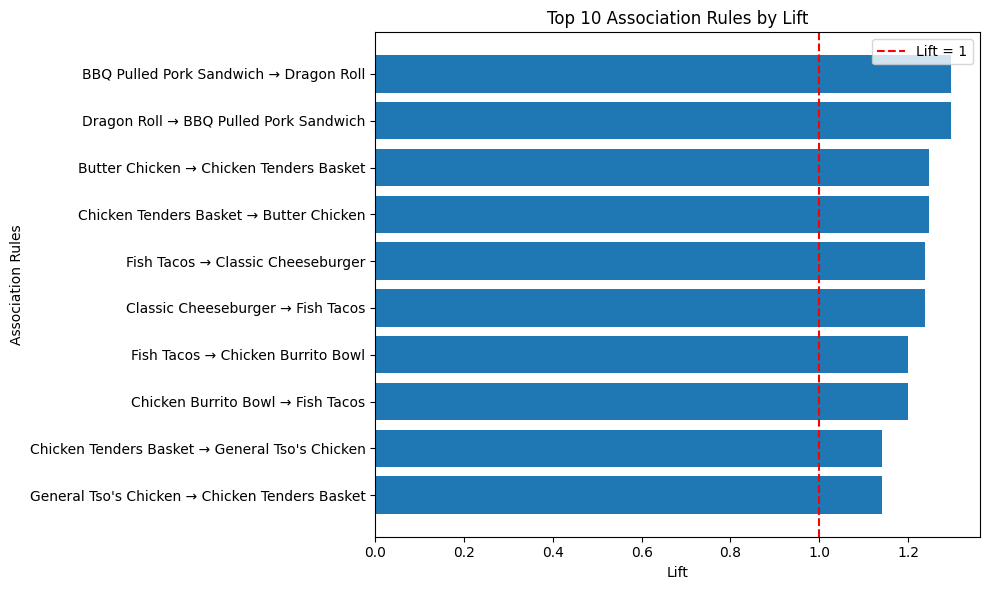

In [46]:
# Visualization
plt.figure(figsize=(10, 6))

rule_labels = (
    top_10_rules["antecedents"]
    + " → "
    + top_10_rules["consequents"]
)

plt.barh(rule_labels, top_10_rules["lift"])

plt.xlabel("Lift")
plt.ylabel("Association Rules")
plt.title("Top 10 Association Rules by Lift")
plt.axvline(x=1, linestyle="--", color="red", label="Lift = 1")
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [47]:
basket_df.to_csv("processed_baskets.csv", index=False)
rules_clean.to_csv("association_rules.csv", index=False)